In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from sqlalchemy import create_engine

engine = create_engine(
    "mssql+pyodbc://@localhost/Scorecard"
    "?driver=ODBC+Driver+17+for+SQL+Server&trusted_connection=yes"
)

earn  = pd.read_sql("SELECT * FROM vw_program_earnings", engine)
value = pd.read_sql("SELECT * FROM vw_program_value", engine)
print(earn.shape, value.shape)

(49931, 17) (26436, 20)


                                        count      mean      std      min  \
CREDDESC                                                                    
Associate's Degree                     7641.0   54345.0  18096.0  12551.0   
Bachelor's Degree                     24822.0   64126.0  20896.0  16087.0   
Doctoral Degree                        1084.0  106449.0  33070.0  33204.0   
First Professional Degree               679.0  117917.0  39832.0  25985.0   
Graduate/Professional Certificate       353.0   94903.0  44336.0  28595.0   
Master's Degree                        9445.0   84010.0  32276.0  19737.0   
Post-baccalaureate Certificate           90.0   82836.0  30689.0  36174.0   
Undergraduate Certificate or Diploma   5817.0   45104.0  17720.0   8305.0   

                                          25%       50%       75%       max  
CREDDESC                                                                     
Associate's Degree                    41445.0   49858.0   64309.0  163641

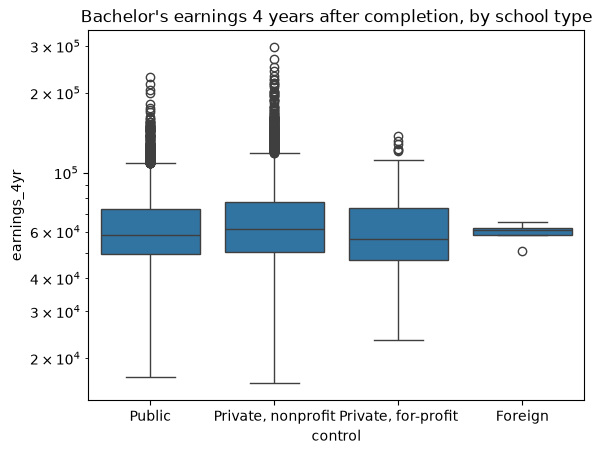

In [2]:
print(earn.groupby("CREDDESC")["earnings_4yr"].describe().round(0))

bach = earn[earn["CREDLEV"] == "3"]
sns.boxplot(data=bach, x="control", y="earnings_4yr")
plt.yscale("log")
plt.title("Bachelor's earnings 4 years after completion, by school type")
plt.show()

In [3]:
def fit_models(min_n):
    d = earn[(earn["CREDLEV"] == "3") & (earn["earnings_count"] >= min_n)]
    d = d.dropna(subset=["earnings_4yr", "control", "admission_rate", "pell_share"]).copy()
    d["log_earn"] = np.log(d["earnings_4yr"])
    field  = smf.ols("log_earn ~ C(CIPCODE)", d).fit()
    school = smf.ols("log_earn ~ C(control) + admission_rate + pell_share", d).fit()
    both   = smf.ols("log_earn ~ C(CIPCODE) + C(control) + admission_rate + pell_share", d).fit()
    return {"min_n": min_n, "rows": len(d),
            "field_only": round(field.rsquared_adj, 3),
            "school_only": round(school.rsquared_adj, 3),
            "both": round(both.rsquared_adj, 3)}

print(pd.DataFrame([fit_models(n) for n in [20, 30, 50]]))

   min_n   rows  field_only  school_only   both
0     20  20248       0.622        0.120  0.704
1     30  15328       0.647        0.131  0.730
2     50   9936       0.672        0.141  0.753


In [4]:
d = earn[(earn["CREDLEV"] == "3") & (earn["earnings_count"] >= 30)
         & (earn["control"] != "Foreign")]
d = d.dropna(subset=["earnings_4yr", "control", "admission_rate",
                     "pell_share", "state"]).copy()
d["log_earn"] = np.log(d["earnings_4yr"])

m_both = smf.ols("log_earn ~ C(CIPCODE) + C(control) + admission_rate + pell_share",
                 d).fit(cov_type="HC1")
m_full = smf.ols("log_earn ~ C(CIPCODE) + C(control) + admission_rate + pell_share + C(state)",
                 d).fit(cov_type="HC1")

# Effect of school traits within the same field (log scale: 0.10 is about +10%)
terms = m_both.params.filter(regex="control|admission_rate|pell_share").index
out = pd.concat([m_both.params[terms], m_both.conf_int().loc[terms]], axis=1)
out.columns = ["coef", "ci_low", "ci_high"]
print(out.round(3))

print("Both:", round(m_both.rsquared_adj, 3), " Both + state:", round(m_full.rsquared_adj, 3))

                                   coef  ci_low  ci_high
C(control)[T.Private, nonprofit]  0.014  -0.024    0.053
C(control)[T.Public]             -0.020  -0.059    0.018
admission_rate                   -0.187  -0.203   -0.171
pell_share                       -0.466  -0.497   -0.435
Both: 0.73  Both + state: 0.798


In [5]:
v = value[(value["CREDLEV"] == "3") & (value["earnings_count"] >= 30)
          & (value["debt_count"] >= 30) & (value["control"] != "Foreign")]
v = v.dropna(subset=["UNITID"]).copy()

# Raw medians by school type
print(v.groupby("control").agg(
    programs=("earnings_4yr", "size"),
    median_earnings=("earnings_4yr", "median"),
    median_debt=("median_debt", "median"),
    median_earn_to_debt=("earnings_to_debt", "median")).round(2))

# Same field, different school type, with errors clustered by school
v["log_earn"] = np.log(v["earnings_4yr"])
v["log_debt"] = np.log(v["median_debt"])
for y in ["log_earn", "log_debt"]:
    m = smf.ols(f"{y} ~ C(CIPCODE) + C(control)", v).fit(
        cov_type="cluster", cov_kwds={"groups": v["UNITID"]})
    ci = m.conf_int().filter(like="control", axis=0)
    ci.columns = ["ci_low", "ci_high"]
    print("\n", y)
    print(pd.concat([m.params.filter(like="control").rename("coef"), ci], axis=1).round(3))

                     programs  median_earnings  median_debt  \
control                                                       
Private, for-profit       284          57310.5      35324.0   
Private, nonprofit       3394          66596.5      25000.0   
Public                   8686          59199.0      21250.0   

                     median_earn_to_debt  
control                                   
Private, for-profit                 1.60  
Private, nonprofit                  2.76  
Public                              2.96  

 log_earn
                                   coef  ci_low  ci_high
C(control)[T.Private, nonprofit]  0.140   0.094    0.187
C(control)[T.Public]              0.071   0.026    0.116

 log_debt
                                   coef  ci_low  ci_high
C(control)[T.Private, nonprofit] -0.324  -0.438   -0.211
C(control)[T.Public]             -0.453  -0.565   -0.340


In [6]:
# How many different schools sit behind the 646 for-profit programs?
fp = v[v["control"] == "Private, for-profit"]
print("For-profit programs:", len(fp), " distinct schools:", fp["UNITID"].nunique())

# Question 4: programs far above or below the national median for their field
q = earn[(earn["CREDLEV"] == "3") & (earn["earnings_count"] >= 30)]
q = q.dropna(subset=["national_median_earnings"]).copy()
q["vs_national"] = q["earnings_4yr"] / q["national_median_earnings"] - 1

cols = ["INSTNM", "CIPDESC", "state", "control", "earnings_4yr",
        "national_median_earnings", "vs_national", "earnings_count"]
print(q.nlargest(15, "vs_national")[cols].round(2))
print(q.nsmallest(15, "vs_national")[cols].round(2))
print(q.groupby("control")["vs_national"].median().round(3))

For-profit programs: 284  distinct schools: 66
                                      INSTNM  \
19683              University of the Pacific   
48405                    Bellevue University   
3952   Massachusetts Institute of Technology   
4964        University of Michigan-Ann Arbor   
31183             Carnegie Mellon University   
31075             University of Pennsylvania   
25994  Massachusetts Institute of Technology   
18513             Carnegie Mellon University   
18514             Carnegie Mellon University   
10381                  University of Chicago   
19535             University of Pennsylvania   
12774             Carnegie Mellon University   
19161                      Carlow University   
18767   University of California-Los Angeles   
37881           Union Institute & University   

                                                 CIPDESC state  \
19683             Multi/Interdisciplinary Studies, Other    CA   
48405  Business Operations Support and Assistant Ser

In [7]:
key = ["OPEID6", "CIPCODE", "CREDLEV"]

g = earn.groupby(key).size()
print("Groups with 2+ rows:", (g > 1).sum(),
      "| rows inside them:", g[g > 1].sum(), "of", len(earn))

same = earn.groupby(key).agg(n=("earnings_4yr", "size"),
                             distinct_earn=("earnings_4yr", "nunique"))
multi = same[same["n"] > 1]
print("Share of those groups with identical earnings:",
      round((multi["distinct_earn"] == 1).mean(), 3))

Groups with 2+ rows: 0 | rows inside them: 0 of 49931
Share of those groups with identical earnings: nan
